## Uplift Modeling: Who Should Get the Email?

In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

sys.path.insert(0, "../src")
from uplift import TLearner, make_features, qini_coefficient, qini_curve, share_of_gain_at, uplift_by_decile

EMAIL = "Womens E-Mail"          # rerun with "Mens E-Mail" to compare
df = pd.read_csv("../data/hillstrom.csv")
df = df[df["segment"].isin([EMAIL, "No E-Mail"])].reset_index(drop=True)
X = make_features(df)
t = (df["segment"] == EMAIL).astype(int)
y = df["visit"]
strata = t.astype(str) + "_" + y.astype(str)          # keep treatment and outcome mix equal in both halves
X_tr, X_te, y_tr, y_te, t_tr, t_te = train_test_split(X, y, t, test_size=0.3, stratify=strata, random_state=42)
print(X_tr.shape, X_te.shape)

(29885, 9) (12808, 9)


In [2]:
base = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=42)
tl = TLearner(base).fit(X_tr, y_tr, t_tr)
up_te = tl.predict_uplift(X_te)
print(f"Average predicted uplift: {up_te.mean():.3f}")
print(f"Actual average uplift in test set: {y_te[t_te == 1].mean() - y_te[t_te == 0].mean():.3f}")

Average predicted uplift: 0.045
Actual average uplift in test set: 0.045


## Uplift model
A T-learner (two XGBoost models, one trained on emailed customers and one on control) estimates each customer's extra chance of visiting because of the women's email. On the test set, the average predicted uplift was 0.045 vs. an actual uplift of 0.045, so the predictions are well calibrated on average. Next: does the model rank customers correctly, putting the persuadables at the top?

In [3]:
deciles = uplift_by_decile(up_te, y_te, t_te)
deciles.round(3)

,customers,predicted_uplift,rate_email,rate_control,actual_uplift
bin,,,,,
1,1281,0.120,0.184,0.134,0.050
2,1281,0.091,0.170,0.111,0.059
3,1281,0.076,0.187,0.098,0.089
4,1280,0.063,0.155,0.094,0.061
5,1281,0.051,0.174,0.104,0.070
6,1281,0.037,0.120,0.108,0.012
7,1280,0.025,0.127,0.106,0.021
8,1281,0.014,0.109,0.076,0.033
9,1281,0.001,0.128,0.104,0.024


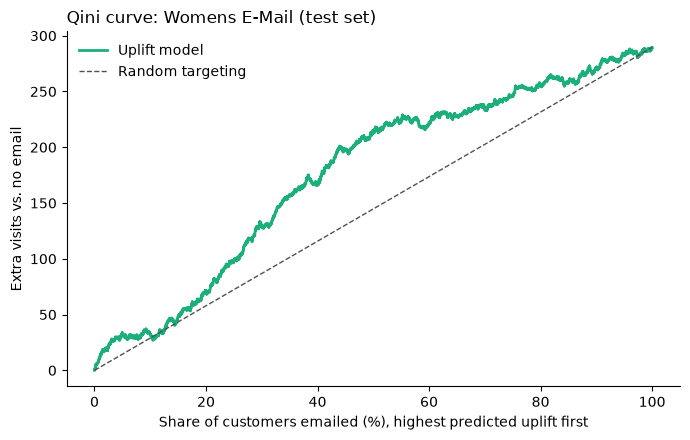

Qini coefficient: 31.8  (above 0 = better than random)
Emailing the top 20% captures 24% of the extra visits
Emailing the top 30% captures 44% of the extra visits
Emailing the top 50% captures 74% of the extra visits


In [4]:
curve = qini_curve(up_te, y_te, t_te)
q = qini_coefficient(curve)
total = curve["incremental_visits"].iloc[-1]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(curve["share_targeted"] * 100, curve["incremental_visits"], color="#1baf7a", linewidth=2, label="Uplift model")
ax.plot([0, 100], [0, total], color="#52514e", linestyle="--", linewidth=1, label="Random targeting")
ax.set_xlabel("Share of customers emailed (%), highest predicted uplift first")
ax.set_ylabel("Extra visits vs. no email")
ax.set_title(f"Qini curve: {EMAIL} (test set)", loc="left")
ax.legend(frameon=False)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(f"../reports/figures/03_qini_curve_{EMAIL.split()[0]}.png", dpi=150)
plt.show()
print(f"Qini coefficient: {q:.1f}  (above 0 = better than random)")
for share in (0.2, 0.3, 0.5):
    print(f"Emailing the top {share:.0%} captures {share_of_gain_at(curve, share):.0%} of the extra visits")

In [5]:
rule_col = "womens" if EMAIL.startswith("Womens") else "mens"
test = X_te.assign(y=y_te.values, t=t_te.values, pred=up_te)

def uplift(s):
    return s.loc[s.t == 1, "y"].mean() - s.loc[s.t == 0, "y"].mean()

rule = test[rule_col] == 1
share = rule.mean()                                            # what share of customers the rule emails
model_top = test["pred"] >= test["pred"].quantile(1 - share)   # model picks the SAME number of customers
rows = {
    f"Rule: past {rule_col} buyers": (rule.sum(), uplift(test[rule])),
    "Rule: everyone else": ((~rule).sum(), uplift(test[~rule])),
    f"Model: top {share:.0%}": (model_top.sum(), uplift(test[model_top])),
    f"Model: bottom {1 - share:.0%}": ((~model_top).sum(), uplift(test[~model_top])),
    "Email everyone": (len(test), uplift(test)),
}
result = pd.DataFrame(rows, index=["customers", "actual_uplift"]).T
result["customers"] = result["customers"].astype(int)
result.round(3)

,customers,actual_uplift
Rule: past womens buyers,7069,0.077
Rule: everyone else,5739,0.006
Model: top 55%,7069,0.064
Model: bottom 45%,5739,0.021
Email everyone,12808,0.045


## Did the model find the persuadables?
The uplift model beats random targeting (Qini coefficient 31.8). Emailing only the top 30% of customers by predicted uplift captures 44% of the extra visits, and the top 50% captures 74%, compared with 30% and 50% for random targeting. By decile, the top half (bins 1–5) averaged about 6.6 extra visit points from the email vs. about 2.4 in the bottom half, roughly 2.75x the effect.

Two weaknesses: the model is overconfident at the extremes. The top decile was predicted at +12.0 points but delivered +5.0 (many were "sure things" who visit anyway; control visit rate 13.4%), and the bottom decile was predicted to be hurt by the email (−2.7) but actually gained +2.9. Every decile showed a positive effect, so there are no true "do-not-disturb" customers. Business takeaway: if emails are cheap, send to everyone; if each email has a cost, targeting the top half keeps about three-quarters of the benefit at half the volume.

## Model vs. a simple rule
Women's email: the rule "email only past women's buyers" (55% of customers) had an actual uplift of 0.077, vs. 0.006 for everyone else. The model's top 55% (same email count) had 0.064, vs. 0.021 for the rest. The simple rule beat the model: it captures roughly 94% of the extra visits with 55% of the emails, vs. about 79% for the model. The model's positive Qini (31.8) came mostly from partially rediscovering the womens column, which the rule uses directly without noise.

Men's email: average uplift 0.077 (actual 0.077), larger than the women's email. Uplift was flat across deciles (0.051–0.104), the Qini coefficient was −0.1, and the top 50% captured exactly 50% of the extra visits: the model could not beat random targeting. The rule showed past men's buyers at 0.085 vs. 0.067 for everyone else, so the men's email works on nearly everyone, and skipping non-buyers would give up about 39% of its benefit.

Takeaway: with only nine customer facts, a T-learner adds no value over domain common sense here. The women's email should go to past women's buyers only; the men's email should go to everyone. Testing ML against a simple rule is what revealed this.

In [6]:
full = pd.read_csv("../data/hillstrom.csv")
full["buyer_type"] = np.select(
    [(full["mens"] == 1) & (full["womens"] == 1), full["womens"] == 1, full["mens"] == 1],
    ["Bought both", "Women's only", "Men's only"], default="Neither")
rows = []
for btype, g in full.groupby("buyer_type"):
    ctrl = g.loc[g["segment"] == "No E-Mail", "visit"].mean()
    rows.append({"buyer_type": btype, "customers": len(g),
                 "mens_email_uplift": g.loc[g["segment"] == "Mens E-Mail", "visit"].mean() - ctrl,
                 "womens_email_uplift": g.loc[g["segment"] == "Womens E-Mail", "visit"].mean() - ctrl})
who = pd.DataFrame(rows).set_index("buyer_type")
who["best_email"] = np.where(who["mens_email_uplift"] >= who["womens_email_uplift"], "Mens", "Womens")
who.round(3)

,customers,mens_email_uplift,womens_email_uplift,best_email
buyer_type,,,,
Bought both,6448,0.134,0.071,Mens
Men's only,28818,0.069,0.011,Mens
Women's only,28734,0.071,0.074,Womens


## Recommendation
Assumptions (stated, not measured): $0.01 per email, $0.50 per extra visit, so an email pays for itself only when its uplift is above 2 points.

1. Send the men's email to everyone. It lifts visits in every customer group: +13.4 points for customers who bought both categories, +6.9 for men's-only buyers, and +7.1 for women's-only buyers. Net value is about $2,850 per 100,000 customers.
2. Retire the women's email. It only works on past women's buyers (+7.4 points), where it ties the men's email (+7.1; the gap is within noise), and for men's-only buyers its uplift (+1.1) is below break-even. Even its best targeting (past women's buyers only) earns about $1,565 per 100,000, roughly half the men's email.
3. The uplift model: it confirmed these patterns but did not beat a simple rule for the women's email and found no one to target for the men's email, because the men's email helps nearly everyone. With only nine customer features, simple group comparisons were the better decision tool.
4. Limitation: each customer received at most one email, so we cannot say what happens if a customer gets both.
5. Next test: men's email to everyone vs. a new women's email design for women's buyers, to see if a better women's email can beat the men's email in its own audience.